# 05 - CNN Desde Cero (Linea Base Sin Pre-entrenamiento)
## Enfoque Oficial Estrictamente Sin Aumento de Datos (Split 80/20)

**Protocolo de Evaluacion Clinica (7 Pasos):**
- **Particion Agrupada por Paciente y Estratificada (80/20):**
  - **Train:** 264 imagenes originales (`split_sin_aumento_80_20.csv`).
  - **Validacion:** 66 imagenes originales (`split_sin_aumento_80_20.csv`).
  - **Test Independiente (Parte A):** 83 imagenes originales (`test_sin_aumento_83.csv`).
- **Cero Aumento de Datos:** Sin rotaciones, flips ni replicas sinteticas.
- **Arquitectura:** Red Convolucional de 4 bloques entrenada desde cero sin pesos pre-entrenados.
- **Protocolo Identico:** `EarlyStopping(monitor='val_loss', patience=6)` y umbral $\tau = 0.50$.
- **GPU:** NVIDIA GeForce RTX 4050 Laptop GPU (CUDA).

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
import csv
import copy
import random
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, brier_score_loss
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo activo: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"})')

Dispositivo activo: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


## 1. Carga del Split Oficial Sin Aumento de Datos (264 Train / 66 Val / 83 Test)

In [2]:
split_dev_csv = '../data_splits/split_sin_aumento_80_20.csv'
split_test_csv = '../data_splits/test_sin_aumento_83.csv'

train_records, val_records, test_records = [], [], []

with open(split_dev_csv, mode='r', encoding='utf-8') as f:
    for row in csv.DictReader(f):
        item = {'image_name': row['Image name'], 'label': int(row['binary_label']), 'file_path': os.path.join('../../', row['file_path'])}
        if row['split'] == 'train':
            train_records.append(item)
        elif row['split'] == 'val':
            val_records.append(item)

with open(split_test_csv, mode='r', encoding='utf-8') as f:
    for row in csv.DictReader(f):
        test_records.append({'image_name': row['Image name'], 'label': int(row['binary_label']), 'file_path': os.path.join('../../', row['file_path'])})

print(f'Entrenamiento (Train): {len(train_records)} imagenes originales (100% sin aumento)')
print(f'Validacion (Val):      {len(val_records)} imagenes originales (100% sin aumento)')
print(f'Prueba (Test Parte A): {len(test_records)} imagenes originales (100% sin aumento)')

Entrenamiento (Train): 264 imagenes originales (100% sin aumento)
Validacion (Val):      66 imagenes originales (100% sin aumento)
Prueba (Test Parte A): 83 imagenes originales (100% sin aumento)


## 2. Pipeline de Preprocesamiento Puro (Cero Data Augmentation)

In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# Unicamente redimensionado y normalizacion ImageNet (CERO transformaciones de aumento)
pure_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class IDRiDPureDataset(Dataset):
    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = Image.open(rec['file_path']).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(rec['label'], dtype=torch.float32)

train_loader = DataLoader(IDRiDPureDataset(train_records, pure_transform), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(IDRiDPureDataset(val_records, pure_transform), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(IDRiDPureDataset(test_records, pure_transform), batch_size=BATCH_SIZE, shuffle=False)
print('DataLoaders listos sin ninguna tecnica de aumento de datos.')

DataLoaders listos sin ninguna tecnica de aumento de datos.


## 3. Construcción de la Arquitectura (05 - CNN Desde Cero (Linea Base Sin Pre-entrenamiento))

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = SimpleCNN().to(device)
print('CNN desde cero inicializada en GPU.')

CNN desde cero inicializada en GPU.


## 4. Entrenamiento con Protocolo Idéntico (`EarlyStopping` en `val_loss`)

In [5]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

EPOCHS = 18
PATIENCE = 5
best_val_loss = float('inf')
best_weights = copy.deepcopy(model.state_dict())
patience_counter = 0
history = {'train_loss': [], 'val_loss': [], 'val_auc': []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
    train_loss = running_loss / len(train_loader.dataset)

    model.eval()
    val_loss_sum = 0.0
    val_probs, val_trues = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels_gpu = imgs.to(device), labels.to(device).unsqueeze(1)
            logits = model(imgs)
            loss = criterion(logits, labels_gpu)
            val_loss_sum += loss.item() * imgs.size(0)
            probs = torch.sigmoid(logits).cpu().numpy().ravel()
            val_probs.extend(probs)
            val_trues.extend(labels.numpy())

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_auc = roc_auc_score(val_trues, val_probs)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)

    status = ''
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        torch.save(best_weights, '../modelos_guardados/cnn_scratch_sin_aumento.pt')
        patience_counter = 0
        status = ' [MEJOR VAL_LOSS - GUARDADO]'
    else:
        patience_counter += 1

    print(f'Epoca {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f}{status}')
    if patience_counter >= PATIENCE:
        print(f'Early Stopping activado en epoca {epoch}. Restaurando mejores pesos (val_loss={best_val_loss:.4f}).')
        break

model.load_state_dict(best_weights)

Epoca 01/18 | Train Loss: 0.6348 | Val Loss: 0.6966 | Val AUC: 0.6873 [MEJOR VAL_LOSS - GUARDADO]


Epoca 02/18 | Train Loss: 0.6071 | Val Loss: 0.6685 | Val AUC: 0.7263 [MEJOR VAL_LOSS - GUARDADO]


Epoca 03/18 | Train Loss: 0.5861 | Val Loss: 0.5892 | Val AUC: 0.7146 [MEJOR VAL_LOSS - GUARDADO]


Epoca 04/18 | Train Loss: 0.5484 | Val Loss: 0.5844 | Val AUC: 0.7302 [MEJOR VAL_LOSS - GUARDADO]


Epoca 05/18 | Train Loss: 0.5653 | Val Loss: 0.5630 | Val AUC: 0.7663 [MEJOR VAL_LOSS - GUARDADO]


Epoca 06/18 | Train Loss: 0.5255 | Val Loss: 0.5809 | Val AUC: 0.7634


... (9 outputs left out)

Epoca 16/18 | Train Loss: 0.5210 | Val Loss: 0.5510 | Val AUC: 0.7673


Epoca 17/18 | Train Loss: 0.4959 | Val Loss: 0.5416 | Val AUC: 0.8054


Epoca 18/18 | Train Loss: 0.5108 | Val Loss: 0.5836 | Val AUC: 0.7761


<All keys matched successfully>

## 5. Evaluación Oficial en Validación (N=66) y Test (N=83) con IC 95% (Umbral 0.5)

In [6]:
def predict_loader(loader):
    model.eval()
    all_probs, all_trues = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            logits = model(imgs.to(device))
            probs = torch.sigmoid(logits).cpu().numpy().ravel()
            all_probs.extend(probs)
            all_trues.extend(labels.numpy())
    return np.array(all_trues), np.array(all_probs)

def bootstrap_ci(y_true, y_prob, metric_fn, n_boot=1000):
    rng = np.random.RandomState(SEED)
    stats = []
    for _ in range(n_boot):
        idx = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        stats.append(metric_fn(y_true[idx], y_prob[idx]))
    return np.percentile(stats, [2.5, 97.5])

def report_metrics(split_name, y_true, y_prob, threshold=0.50):
    y_pred = (y_prob >= threshold).astype(int)
    auc_v = roc_auc_score(y_true, y_prob)
    acc_v = accuracy_score(y_true, y_pred)
    rec_v = recall_score(y_true, y_pred)
    f1_v  = f1_score(y_true, y_pred)
    brier = brier_score_loss(y_true, y_prob)
    cm    = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    spec_v = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    auc_ci = bootstrap_ci(y_true, y_prob, roc_auc_score)
    acc_ci = bootstrap_ci(y_true, y_pred, accuracy_score)
    f1_ci  = bootstrap_ci(y_true, y_pred, f1_score)

    print(f'=== {split_name} (N={len(y_true)}, Umbral={threshold}) ===')
    print(f'ROC-AUC:       {auc_v:.4f} [IC 95%: {auc_ci[0]:.4f} - {auc_ci[1]:.4f}]')
    print(f'Accuracy:      {acc_v:.4f} [IC 95%: {acc_ci[0]:.4f} - {acc_ci[1]:.4f}]')
    print(f'Sensibilidad:  {rec_v:.4f} | Especificidad: {spec_v:.4f}')
    print(f'F1-Score:      {f1_v:.4f} [IC 95%: {f1_ci[0]:.4f} - {f1_ci[1]:.4f}]')
    print(f'Brier Score:   {brier:.4f}')
    print(f'Matriz Confusion: TN={tn}, FP={fp}, FN={fn}, TP={tp}\n')

val_y, val_p   = predict_loader(val_loader)
test_y, test_p = predict_loader(test_loader)

report_metrics('VALIDACION INTERNA (66 Originales)', val_y, val_p)
report_metrics('TEST INDEPENDIENTE PARTE A (83 Originales)', test_y, test_p)

=== VALIDACION INTERNA (66 Originales) (N=66, Umbral=0.5) ===
ROC-AUC:       0.8171 [IC 95%: 0.6926 - 0.9232]
Accuracy:      0.8030 [IC 95%: 0.6970 - 0.8939]
Sensibilidad:  0.9268 | Especificidad: 0.6000
F1-Score:      0.8539 [IC 95%: 0.7674 - 0.9247]
Brier Score:   0.1735
Matriz Confusion: TN=15, FP=10, FN=3, TP=38



=== TEST INDEPENDIENTE PARTE A (83 Originales) (N=83, Umbral=0.5) ===
ROC-AUC:       0.9125 [IC 95%: 0.8419 - 0.9698]
Accuracy:      0.8554 [IC 95%: 0.7711 - 0.9277]
Sensibilidad:  0.9423 | Especificidad: 0.7097
F1-Score:      0.8909 [IC 95%: 0.8222 - 0.9457]
Brier Score:   0.1355
Matriz Confusion: TN=22, FP=9, FN=3, TP=49



## 6. Curvas de Aprendizaje (Pérdida y AUC en Validación)

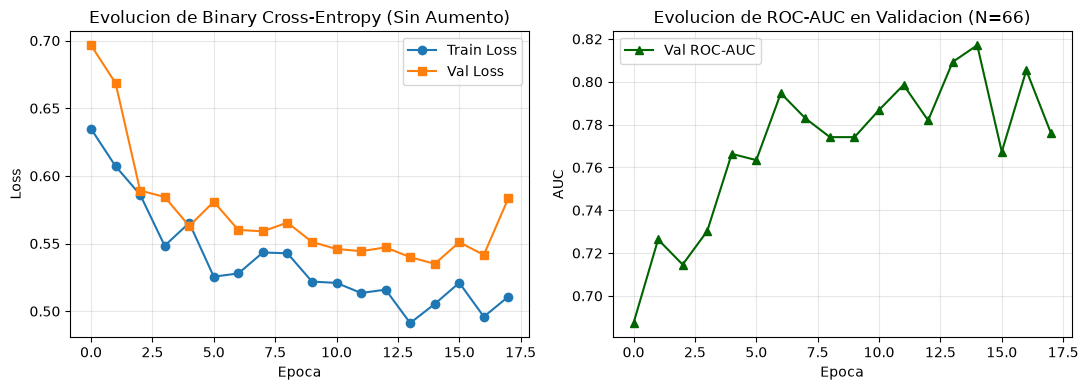

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history['train_loss'], label='Train Loss', marker='o')
ax[0].plot(history['val_loss'], label='Val Loss', marker='s')
ax[0].set_title('Evolucion de Binary Cross-Entropy (Sin Aumento)')
ax[0].set_xlabel('Epoca')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(history['val_auc'], color='darkgreen', label='Val ROC-AUC', marker='^')
ax[1].set_title('Evolucion de ROC-AUC en Validacion (N=66)')
ax[1].set_xlabel('Epoca')
ax[1].set_ylabel('AUC')
ax[1].legend()
ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Explicabilidad Clínica (Grad-CAM sobre Imagen Original de Test)

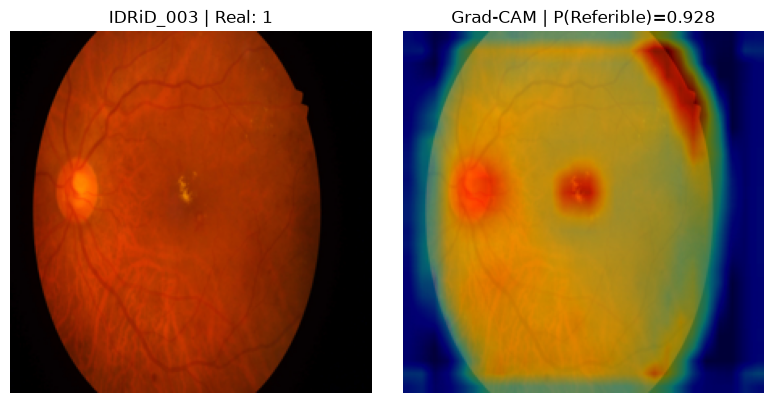

In [8]:
target_layer = model.features[-4]
activations, gradients = [], []

def forward_hook(module, inp, out):
    activations.append(out.detach())
    out.register_hook(lambda grad: gradients.append(grad.detach()))

h1 = target_layer.register_forward_hook(forward_hook)

sample_rec = test_records[0]
orig_pil = Image.open(sample_rec['file_path']).convert('RGB').resize((224, 224))
inp_tensor = pure_transform(orig_pil).unsqueeze(0).to(device)

model.eval()
model.zero_grad()
logit = model(inp_tensor)
prob = torch.sigmoid(logit).item()
logit.backward()

act = activations[0].cpu()[0]
grad = gradients[0].cpu()[0]
weights = grad.mean(dim=(1, 2), keepdim=True)
cam = torch.relu((weights * act).sum(dim=0)).numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

h1.remove()

cam_resized = np.array(Image.fromarray(np.uint8(cam * 255)).resize((224, 224), Image.BILINEAR)) / 255.0

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig_pil)
axes[0].set_title(f"{sample_rec['image_name']} | Real: {sample_rec['label']}")
axes[0].axis('off')

axes[1].imshow(orig_pil)
axes[1].imshow(cam_resized, cmap='jet', alpha=0.45)
axes[1].set_title(f'Grad-CAM | P(Referible)={prob:.3f}')
axes[1].axis('off')
plt.tight_layout()
plt.show()